# Activation Functions — worked study copy

Answers prepared for revision with AI assistance. IBM / Skills Network source notices and embedded instructor explanations are retained. This is not a course submission.

Code completion and execution are tracked separately in the [solution progress report](../../../docs/SOLUTION_PROGRESS.md). Training may require a separate environment, external data, compute or provider credentials.

[Original reference](../../../courses/05-deep-learning-with-pytorch/notebooks/activation-functions.ipynb) · [Course notes](../../../courses/05-deep-learning-with-pytorch/README.md)

**BOUNDED SMOKE RUN:** seed 42; CSVs sampled to at most 5,000 rows; one grid setting with two folds; training budgets capped; DataLoaders limited to 12 batches. These outputs are execution checks, not full-run model evaluations.

In [1]:
import os, itertools, random
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
os.environ['TF_NUM_INTRAOP_THREADS'] = '1'
import numpy as np
np.random.seed(42)
random.seed(42)
import pandas as pd
_read_csv = pd.read_csv
def _bounded_csv(*args, **kwargs):
    data = _read_csv(*args, **kwargs)
    return data.sample(n=5000,random_state=42) if len(data)>5000 else data
pd.read_csv = _bounded_csv
from sklearn.model_selection import GridSearchCV
_grid_fit = GridSearchCV.fit
def _bounded_grid(self, *args, **kwargs):
    grids = self.param_grid if isinstance(self.param_grid,list) else [self.param_grid]
    self.param_grid = [{k:list(v)[:1] for k,v in grid.items()} for grid in grids[:1]]
    self.cv = 2
    self.n_jobs = 1
    self.verbose = 0
    return _grid_fit(self,*args,**kwargs)
GridSearchCV.fit = _bounded_grid
try:
    import torch
except ImportError:
    torch = None
if torch is not None:
    torch.manual_seed(42)
    torch.set_num_threads(1)
    _loader_iter = torch.utils.data.DataLoader.__iter__
    def _bounded_loader(self):
        return itertools.islice(_loader_iter(self),12)
    torch.utils.data.DataLoader.__iter__ = _bounded_loader


<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


<h1>Activation Functions</h1> 


**Estimated time needed**: 15 minutes


## Learning Objectives
After completing this lab, you will be able to:
- Apply different activation functions in neural networks</li></ul> 


<h2>Table of Contents</h2>
<p>In this lab, you will cover logistic regression by using PyTorch.</p>

<ol>
<li><a href="#Import-the-Libraries">Import the Libraries</a> 
</li>
<li><a href="#Create-a-Tanh-Object">Create a Tanh Object</a>     
</li>
<li><a href="#Create-a-ReLU-Object">Create a ReLU Object</a>     
</li>
 <li><a href="#Compare-Activation-Functions">Compare Activation Functions</a>     
</li>
<li><a href="#Practice-Session">Practice Session</a>     
</li>
</ol>



## Import the Libraries


We'll need the following libraries


In [2]:
%%time
# Install this lab's dependencies in its isolated environment before execution.
# Install this lab's dependencies in its isolated environment before execution.

CPU times: user 0 ns, sys: 0 ns, total: 0 ns
Wall time: 2.15 µs


In [3]:
# Import the libraries we need for this lab

import torch.nn as nn
import torch

import matplotlib.pyplot as plt
torch.manual_seed(2)

Matplotlib is building the font cache; this may take a moment.


<!--Empty Space for separating topics-->


## Working with a Logistic Function


Create a tensor ranging from -10 to 10: 


In [4]:
# Create a tensor

z = torch.arange(-10, 10, 0.1,).view(-1, 1)

When you use sequential, you can create a sigmoid object: 


In [5]:
# Create a sigmoid object

sig = nn.Sigmoid()

Apply the element-wise function Sigmoid with the object:


In [6]:
# Make a prediction of sigmoid function

yhat = sig(z)

Plot the results: 


Text(0, 0.5, 'yhat')

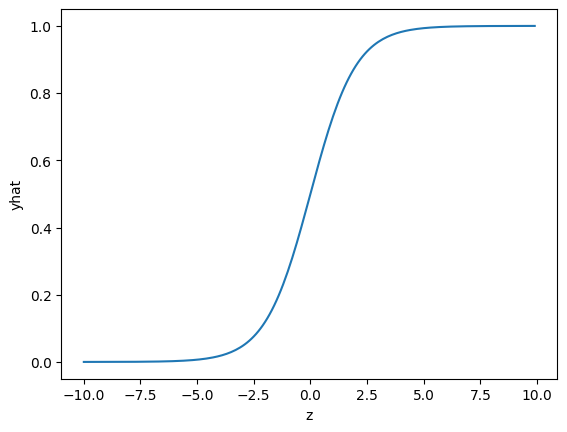

In [7]:
# Plot the result

plt.plot(z.detach().numpy(),yhat.detach().numpy())
plt.xlabel('z')
plt.ylabel('yhat')

For custom modules, call the sigmoid from the torch (<code>nn.functional</code> for the old version), which applies the element-wise sigmoid from the function module and plots the results:


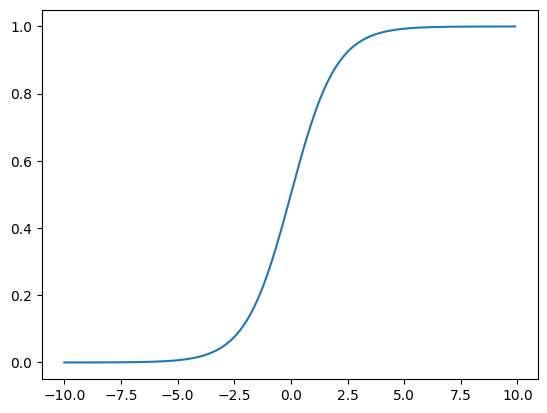

In [8]:
# Use the build in function to predict the result

yhat = torch.sigmoid(z)
plt.plot(z.numpy(), yhat.numpy())

plt.show()

<!--Empty Space for separating topics-->


## Create a Tanh Object


When you use sequential, you can create a tanh object:


In [9]:
# Create a tanh object

TANH = nn.Tanh()

Call the object and plot it:


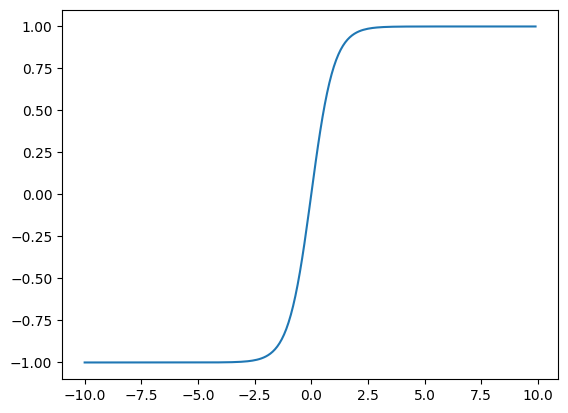

In [10]:
# Make the prediction using tanh object

yhat = TANH(z)
plt.plot(z.numpy(), yhat.numpy())
plt.show()


For custom modules, call the Tanh object from the torch (nn.functional for the old version), which applies the element-wise sigmoid from the function module and plots the results:


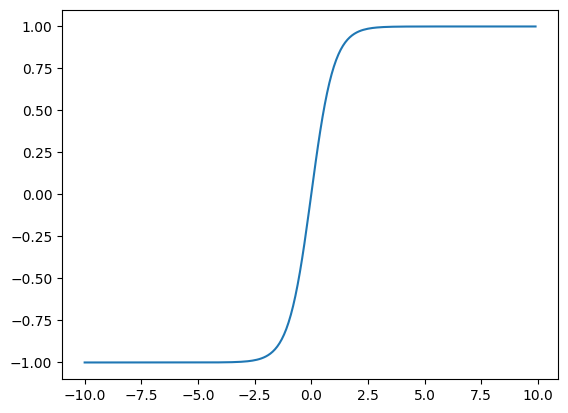

In [11]:
# Make the prediction using the build-in tanh object

yhat = torch.tanh(z)
plt.plot(z.numpy(), yhat.numpy())
plt.show()

<!--Empty Space for separating topics-->


## Create a ReLU Object


When you use sequential, you can create a ReLU object: 


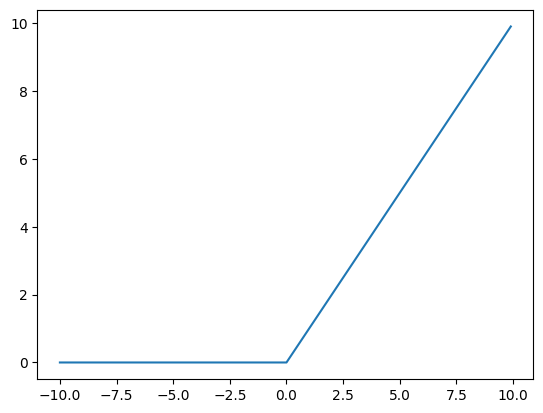

In [12]:
# Create a relu object and make the prediction

RELU = nn.ReLU()
yhat = RELU(z)
plt.plot(z.numpy(), yhat.numpy())

For custom modules, call the relu object from the nn.functional, which applies the element-wise sigmoid from the function module and plots the results:


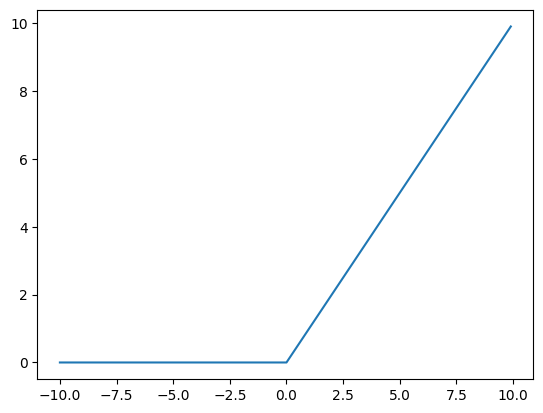

In [13]:
# Use the build-in function to make the prediction

yhat = torch.relu(z)
plt.plot(z.numpy(), yhat.numpy())
plt.show()

## Compare Activation Functions


The following code visualizes and compares the ReLU, sigmoid, and tanh activation functions:


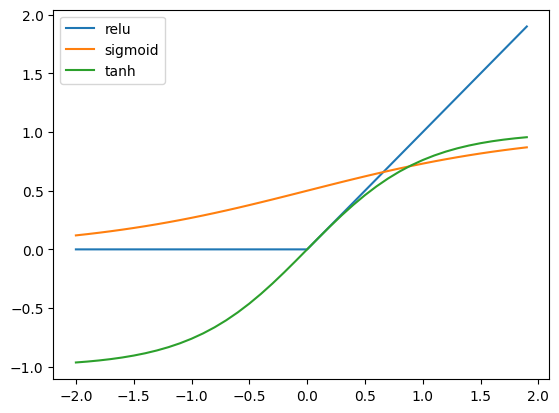

In [14]:
# Plot the results to compare the activation functions

x = torch.arange(-2, 2, 0.1).view(-1, 1)
plt.plot(x.numpy(), torch.relu(x).numpy(), label='relu')
plt.plot(x.numpy(), torch.sigmoid(x).numpy(), label='sigmoid')
plt.plot(x.numpy(), torch.tanh(x).numpy(), label='tanh')
plt.legend()

## Practice Session


Compare the activation functions with a tensor in the range <i>(-1, 1)</i>


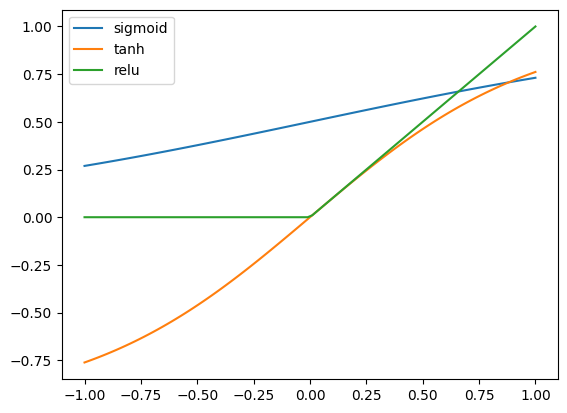

In [15]:
activation_x = torch.linspace(-1,1,100)
for name,values in [('sigmoid',torch.sigmoid(activation_x)),('tanh',torch.tanh(activation_x)),('relu',torch.relu(activation_x))]:
    plt.plot(activation_x.numpy(),values.numpy(),label=name)
plt.legend(); plt.show()

Double-click <b>here</b> for the solution.

<!-- 
x = torch.arange(-1, 1, 0.1).view(-1, 1)
plt.plot(x.numpy(), torch.relu(x).numpy(), label = 'relu')
plt.plot(x.numpy(), torch.sigmoid(x).numpy(), label = 'sigmoid')
plt.plot(x.numpy(), torch.tanh(x).numpy(), label = 'tanh')
plt.legend()
-->


<h2>About the Authors:</h2> 

<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD. 


Other contributors: <a href="https://www.linkedin.com/in/michelleccarey/">Michelle Carey</a>, <a href="https://www.linkedin.com/in/jiahui-mavis-zhou-a4537814a">Mavis Zhou</a>


<!--
## Change Log

|  Date (YYYY-MM-DD) |  Version | Changed By  |  Change Description |
|---|---|---|---|
| 2020-09-23  | 2.0  | Shubham  |  Migrated Lab to Markdown and added to course repo in GitLab |
-->


<hr>





## <h3 align="center"> &#169; IBM Corporation. All rights reserved. <h3/>
